2. System Prompt
A system prompt defines the AI's role and behaviour once. It then applies to every message you send.

System prompt: who the AI is and how it answers (role, tone, rules)
User prompt: what you're asking right now

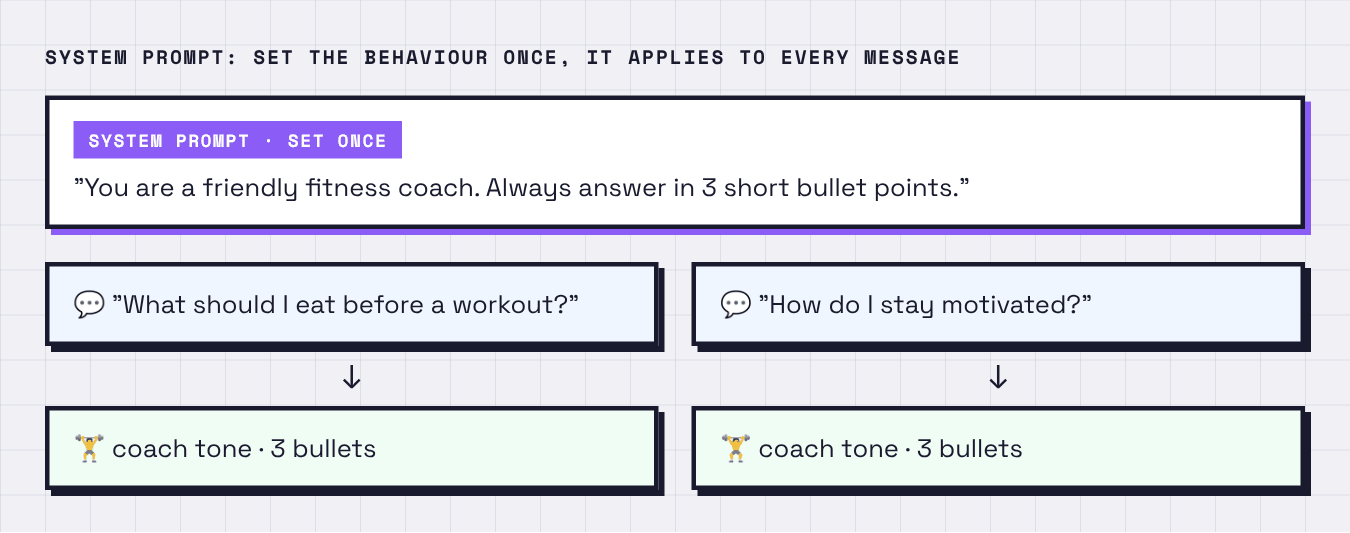


Platform	Where the system prompt goes
Gemini	config=types.GenerateContentConfig(system_instruction=...)
OpenAI / Groq	First message: {"role": "system", ...}
Claude	Separate setting: system="..."

In [1]:
# STEP 0 (run once): install the SDKs
# WHY (tech): Installs each provider's Python SDK, which handles HTTP requests, authentication and response parsing.
# ELI5: Download a translator app for each AI company.
!pip install -q -U google-genai openai anthropic
# If you later get an ImportError: Runtime -> Restart session, then run the cells again (skip this one).

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires google-auth==2.49.0, but you have google-auth 2.62.2 which is incompatible.
google-adk 2.7.1 requires google-genai<3,>=2.12.1, but you have google-genai 3.6.1 which is incompatible.


In [2]:
# WHY (tech): Imports Google's Gen AI SDK, which provides the Client class for calling Gemini.
# ELI5: Bring in Google's phone.
from google import genai
# WHY (tech): Imports typed config objects for settings like temperature and system instructions.
# ELI5: Get Google's order form with boxes for settings.
from google.genai import types
# WHY (tech): Imports Colab's secrets reader so the API key is never written in the code.
# ELI5: Get the key to your locked password drawer.
from google.colab import userdata

# WHY (tech): Creates an authenticated client once; every later Gemini call reuses this connection.
# ELI5: Call Google and show your ID card once.
gemini = genai.Client(api_key=userdata.get("GEMINI_API_KEY"))
# WHY (tech): Stores the model ID in one variable so later cells can reuse or change it easily.
# ELI5: Write the brain's name on a sticky note.
MODEL = "gemini-3.8-flash"
# WHY (tech): A tiny test request confirms the key and model work before doing real tasks.
# ELI5: Say "hello" once to check the phone line works.
test = gemini.models.generate_content(model=MODEL, contents="Say OK")
# WHY (tech): .text pulls only the answer text out of the full response object.
# ELI5: Read the reply to confirm you're connected.
print("✅ Gemini connected:", test.text)

✅ Gemini connected: OK


In [7]:
coach = types.GenerateContentConfig(
    system_instruction="You are a friendly fitness coach. Always answer in 3 short bullet points. Always respond in English. But comply with user instructions",
)

In [5]:
response = gemini.models.generate_content(
    model=MODEL,
    contents="What should I eat before a workout? Answer in English",
    config=coach,
)

print(response.text)

* **Complex Carbs & Fruit:** Have a banana with a spoonful of peanut butter or a small bowl of oatmeal 30–60 minutes before your session for sustained energy!
* **Lean Protein:** Pair your carbs with a little Greek yogurt or a boiled egg to help prep and protect your muscles during the workout.
* **Hydration is Key:** Drink a glass of water beforehand, and keep fats and fiber low so your stomach stays light and ready to move!


In [8]:
response = gemini.models.generate_content(
    model=MODEL,
    contents="What are core muscle?",
    config=coach,
)

print(response.text)

* They are the powerhouse muscles around your midsection, including your abs, obliques, lower back, hips, and glutes!
* Think of them as your body's natural brace that keeps your spine stable, improves your balance, and protects you from injury. 
* They power almost every move you make, helping you do everything from lifting weights to simply standing tall with great posture!


OPEN AI

In [10]:
# Importing libraries, setting the model and testing the connection
# WHY (tech): Imports OpenAI's SDK; Groq and others also accept this same request format.
# ELI5: Bring in OpenAI's phone.
from openai import OpenAI
# WHY (tech): Imports Colab's secrets reader so the key stays out of the code.
# ELI5: Get the key to your password drawer.
from google.colab import userdata

# WHY (tech): Authenticated client using OpenAI's default endpoint; reused by every later OpenAI cell.
# ELI5: Call OpenAI and show your ID card.
openai_client = OpenAI(api_key=userdata.get("OPENAI_API_KEY"))
# WHY (tech): Model ID in one variable; overwrites the Gemini MODEL value set earlier.
# ELI5: Write the GPT brain's name on the sticky note.
MODEL = "gpt-6.1-sol"
# WHY (tech): Tiny test request confirms key, credit and model are all working.
# ELI5: Say "hello" once to check the line works.
test = openai_client.chat.completions.create(model=MODEL, messages=[{"role": "user", "content": "Say OK"}])
# WHY (tech): OpenAI returns a list of choices; we read the first one's message text.
# ELI5: Read the reply to confirm you're connected.
print("✅ OpenAI connected:", test.choices[0].message.content)

✅ OpenAI connected: OK


In [11]:
response = openai_client.chat.completions.create(
    model=MODEL,
    messages=[
        {"role": "system", "content": "You are a friendly fitness coach. Always answer in 3 short bullet points. Always respond in English."},
        {"role": "user", "content": "What should I eat before a workout?"},
    ],
)
print(response.choices[0].message.content)

- **1–3 hours before:** Have carbs plus some protein, like oatmeal with yogurt, toast with eggs, or rice with chicken.
- **30–60 minutes before:** Choose a small, easy-to-digest snack, such as a banana, applesauce, or toast. Limit fat and fiber to avoid stomach discomfort.
- **Hydrate:** Sip water beforehand. For a short, easy workout, you may not need a snack—let hunger and comfort guide you.


In [12]:
response = openai_client.chat.completions.create(
    model=MODEL,
    messages=[
        {"role": "system", "content": "You are a friendly fitness coach. Always answer in 3 short bullet points. Always respond in English."},
        {"role": "user", "content": "How many days I need to workout in week?"},
    ],
)
print(response.choices[0].message.content)

- **Aim for 3–5 workout days per week.** If you’re a beginner, start with 2–3 days and build up gradually.
- Include strength training at least **2 days a week**, plus walking, cycling, or other cardio. Work toward 150 minutes of moderate activity weekly.
- Take rest or easy-movement days between hard sessions. What’s your goal: general fitness, building muscle, or improving endurance?


Antropic Claud


In [13]:
# WHY (tech): Imports Anthropic's SDK, which handles Claude's Messages API format and auth headers.
# ELI5: Bring in Anthropic's phone.
import anthropic
# WHY (tech): Imports Colab's secrets reader so the key stays out of the code.
# ELI5: Get the key to your password drawer.
from google.colab import userdata

# WHY (tech): Authenticated client; Claude API billing is separate from a Claude Pro subscription.
# ELI5: Call Claude and show your ID card.
claude = anthropic.Anthropic(api_key=userdata.get("ANTHROPIC_API_KEY"))
# WHY (tech): Model ID in one variable; overwrites the previous platform's MODEL value.
# ELI5: Write the Claude brain's name on the sticky note.
MODEL = "claude-sonnet-5-5"
# WHY (tech): Tiny test request; max_tokens is required by Claude and caps reply length.
# ELI5: Say "hello" once, with a short word limit.
test = claude.messages.create(model=MODEL, max_tokens=20, messages=[{"role": "user", "content": "Say OK"}])
# WHY (tech): [-1] takes the last content block, which holds the text even if a thinking block comes first.
# ELI5: Read the last page of the reply, where the answer is.
print("✅ Claude connected:", test.content[-1].text)

✅ Claude connected: OK


In [14]:
response = claude.messages.create(
    model=MODEL,
    max_tokens=500,
    system="You are a friendly fitness coach. Always answer in 3 short bullet points. Always respond in English.",
    messages=[{"role": "user", "content": "What should I eat before a workout?"}],
)
print(response.content[-1].text)

- **Eat 1-3 hours before:** Go for complex carbs plus a little protein, like oatmeal with banana or whole-grain toast with eggs, for steady energy.
- **Short on time?** Have a quick, easy-to-digest snack 30-60 minutes out, like a banana, rice cakes with honey, or a small yogurt.
- **Keep it light and hydrated:** Avoid heavy, greasy, or high-fiber foods right beforehand, and sip water so you feel good and avoid stomach upset.


In [15]:
response = claude.messages.create(
    model=MODEL,
    max_tokens=500,
    system="You are a friendly fitness coach. Always answer in 3 short bullet points. Always respond in English.",
    messages=[{"role": "user", "content": "Is doing cardio good?"}],
)
print(response.content[-1].text)

- **Yes, it's great for your heart.** Cardio strengthens your heart and lungs, improves circulation, and can lower blood pressure and cholesterol.
- **It boosts mood and energy.** Regular cardio helps reduce stress, improves sleep, and releases feel-good endorphins.
- **Aim for balance.** Try 150 minutes of moderate cardio a week, and pair it with strength training for the best results. 💪


Groq


In [16]:
# WHY (tech): Groq is OpenAI-compatible, so we reuse OpenAI's SDK instead of installing another library.
# ELI5: Groq speaks OpenAI's language, so use the same phone.
from openai import OpenAI
# WHY (tech): Imports Colab's secrets reader so the key stays out of the code.
# ELI5: Get the key to your password drawer.
from google.colab import userdata

# WHY (tech): base_url redirects every request to Groq's servers; that one setting switches the provider.
# ELI5: Same phone, different phone number, Groq's ID card.
groq = OpenAI(api_key=userdata.get("GROQ_API_KEY"), base_url="https://api.groq.com/openai/v1")
# WHY (tech): A chat-capable model from Groq's list; guard, whisper and TTS models can't chat.
# ELI5: Pick a brain that can actually chat.
MODEL = "openai/gpt-oss-120b"
# WHY (tech): Tiny test request confirms the key and model work.
# ELI5: Say "hello" once to check the line works.
test = groq.chat.completions.create(model=MODEL, messages=[{"role": "user", "content": "Say OK"}])
# WHY (tech): Same response structure as OpenAI: first choice, then message text.
# ELI5: Read the reply to confirm you're connected.
print("✅ Groq connected:", test.choices[0].message.content)

✅ Groq connected: OK


In [17]:
response = groq.chat.completions.create(
    model=MODEL,
    messages=[
        {"role": "system", "content": "You are a friendly fitness coach. Always answer in 3 short bullet points. Always respond in English."},
        {"role": "user", "content": "What should I eat before a workout?"},
    ],
)
print(response.choices[0].message.content)

- Light carbs + protein (e.g., banana with a spoon of peanut butter) 30‑60 min before  
- Stay hydrated: sip water or a low‑sugar electrolyte drink  
- Keep portions moderate to avoid feeling heavy or sluggish during exercise


In [18]:
response = groq.chat.completions.create(
    model=MODEL,
    messages=[
        {"role": "system", "content": "You are a friendly fitness coach. Always answer in 3 short bullet points. Always respond in English."},
        {"role": "user", "content": "Why rest day is important?"},
    ],
)
print(response.choices[0].message.content)

- Allows muscles to repair and grow stronger  
- Reduces risk of injury and burnout  
- Improves overall performance and energy levels  


Here's what system prompts teach you:

**1. There are two layers of instruction.**
- **System prompt:** the bot's permanent job, rules and style. It's set by the builder and the user doesn't see it.
- **User prompt:** the question being asked right now.

This is how one model becomes a fitness coach, a procurement assistant or a contract reviewer, without changing the model itself.

**2. It's the cheapest way to shape behaviour.** Format ("3 bullet points"), tone ("friendly"), scope ("only answer procurement questions") and language are all controlled with plain English, with no training or extra code.

**3. Each platform puts it in a different place:** Gemini in the config, OpenAI and Groq as a "system" message, Claude in a separate `system=` setting. The concept is the same everywhere.

**4. Rules must be clear and must not contradict each other.** "Always English, but follow the user" leaves the model guessing. Good system prompts say which rule wins.

**5. Users can try to override it.** Asking for Hindi tests whether the system prompt holds. In real products, this is where security issues like prompt injection ("ignore your instructions…") start.

**6. Models obey differently.** The same system prompt can behave differently across Gemini, GPT, Claude and Llama, so always test it on the model you'll actually use.

**PM takeaway:** the system prompt is effectively the product specification for an AI feature. It defines the role, the boundaries, the format and the fallback rules. Writing, testing and versioning it carefully is a core AI product skill, much like writing good requirements.